# How Does Gaussian Noise Affect CNN Galaxy Classification?

### Research Question
How does increasing Gaussian noise affect the accuracy of a CNN in classifying synthetic spiral and elliptical galaxies?

### Objective
The goal of this project is to investigate how image noise affects the performance of a Convolutional Neural Network (CNN).

We will generate a small synthetic dataset of spiral and elliptical galaxies, train a simple CNN, and evaluate its accuracy at different noise levels.

### Hypothesis
As Gaussian noise increases, classification accuracy will decrease because the CNN will have more difficulty recognizing galaxy structures.

In [2]:

%pip install tensorflow numpy matplotlib h5py scikit-learn


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 245.6/245.6 MB 37.2 MB/s  0:00:06m0:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.8/2.8 MB 60.6 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 55.5 MB/s  0:00:00m0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 562.6/562.6 kB 15.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 59.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 36.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 38.1 MB/s  0:00:00 eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19/19 [tensorflow]9 [tensorflow]ly]
Note: you may need to restart the kernel to use updated packages.


In [3]:


import numpy as np
import matplotlib.pyplot as plt
import h5py
import tensorflow as tf

from tensorflow.keras import layers, models
from sklearn.model_selection import train_test_split

print("TensorFlow:", tf.__version__)


TensorFlow: 2.22.0-rc0


In [5]:

def create_galaxy(galaxy_type, size=64):
    y, x = np.mgrid[-1:1:complex(size), -1:1:complex(size)]

    angle = np.random.uniform(0, 2*np.pi)
    x_rot = x*np.cos(angle) + y*np.sin(angle)
    y_rot = -x*np.sin(angle) + y*np.cos(angle)

    if galaxy_type == 0:
        # Elliptical galaxy
        a = np.random.uniform(0.3, 0.6)
        b = np.random.uniform(0.2, 0.4)
        image = np.exp(-((x_rot/a)**2 + (y_rot/b)**2))

    else:
        # Spiral galaxy
        r = np.sqrt(x_rot**2 + y_rot**2)
        theta = np.arctan2(y_rot, x_rot)

        arms = np.cos(2*theta - 8*r)**2
        image = np.exp(-4*r) * (0.3 + 0.7*arms)

    return image

# Create 400 images
images = []
labels = []

for i in range(400):
    galaxy_type = i % 2
    images.append(create_galaxy(galaxy_type))
    labels.append(galaxy_type)

images = np.array(images)[..., np.newaxis]
labels = np.array(labels)

print("Dataset shape:", images.shape)



Dataset shape: (400, 64, 64, 1)


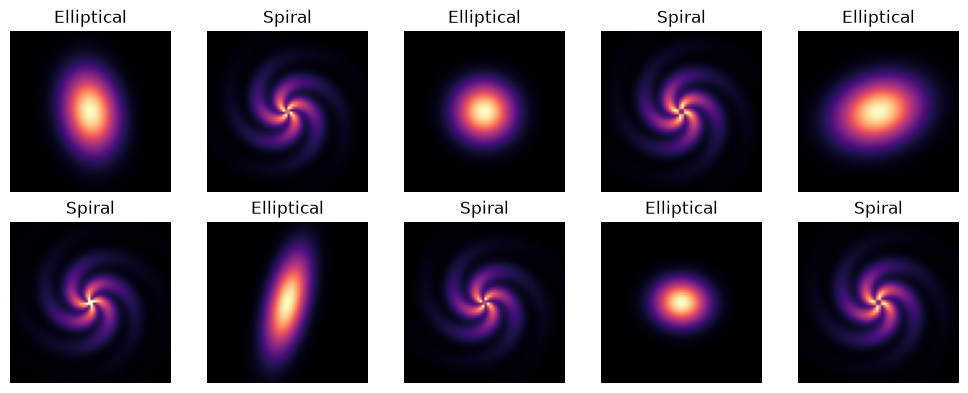

In [6]:

plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(images[i, :, :, 0], cmap="magma")
    plt.title("Elliptical" if labels[i] == 0 else "Spiral")
    plt.axis("off")

plt.tight_layout()
plt.show()


In [7]:

x_train, x_test, y_train, y_test = train_test_split(
    images, labels,
    test_size=0.25,
    random_state=42,
    stratify=labels
)

print("Training:", x_train.shape)
print("Testing:", x_test.shape)


Training: (300, 64, 64, 1)
Testing: (100, 64, 64, 1)


In [8]:

model = models.Sequential([
    layers.Input(shape=(64, 64, 1)),
    layers.Conv2D(8, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(16, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(16, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 62, 62, 8)      │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 31, 31, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 29, 29, 16)     │         1,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 14, 14, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │        50,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 51,457 (201.00 KB)

 Trainable params: 51,457 (201.00 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:

history = model.fit(
    x_train, y_train,
    epochs=10,
    batch_size=16,
    validation_split=0.2,
    verbose=1
)


Epoch 1/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.4958 - loss: 0.6377 - val_accuracy: 1.0000 - val_loss: 0.5562
Epoch 2/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.4400 - val_accuracy: 0.9833 - val_loss: 0.3354
Epoch 3/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.1843 - val_accuracy: 1.0000 - val_loss: 0.1149
Epoch 4/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0460 - val_accuracy: 1.0000 - val_loss: 0.0415
Epoch 5/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0146 - val_accuracy: 1.0000 - val_loss: 0.0118
Epoch 6/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0066 - val_accuracy: 1.0000 - val_loss: 0.0060
Epoch 7/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 0.0034 - val_accuracy: 1.0000 - val_loss: 0.0054
Epoch 8/10
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 0.0026 - val_accuracy: 1.0000 - val_loss

In [19]:

noise_levels = [0, 0.01, 0.02, 0.03, 0.04, 0.05]
noise_levels = np.linspace(0,.1,200)
accuracies = []

rng = np.random.default_rng(42)

for noise in noise_levels:
    noisy_images = x_test + rng.normal(
        0, noise, x_test.shape
    )
    noisy_images = np.clip(noisy_images, 0, 1)

    loss, accuracy = model.evaluate(
        noisy_images, y_test, verbose=0
    )

    accuracies.append(accuracy)
    print(f"Noise: {noise:.1f}, Accuracy: {accuracy:.3f}")


Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy: 1.000
Noise: 0.0, Accuracy

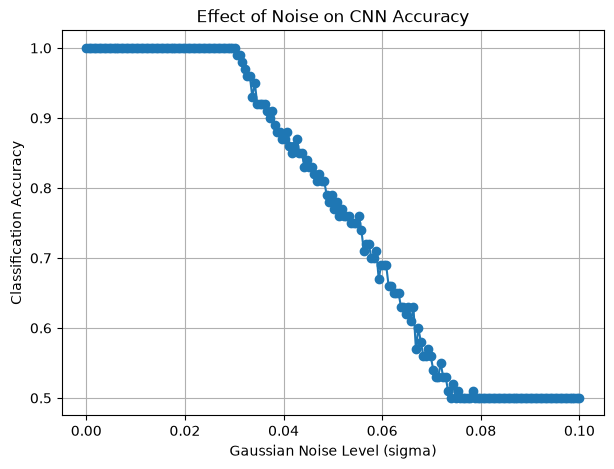

In [20]:

plt.figure(figsize=(7, 5))
plt.plot(noise_levels, accuracies, marker="o")
plt.xlabel("Gaussian Noise Level (sigma)")
plt.ylabel("Classification Accuracy")
plt.title("Effect of Noise on CNN Accuracy")
plt.grid(True)
plt.show()


## Analysis: Why Does CNN Accuracy Decrease with Noise?

The graph shows three different regions of CNN performance.

**1. Low Noise (σ = 0–0.03)**

The classification accuracy remains close to 100%. At low noise levels, the CNN can still recognize the important structural features of spiral and elliptical galaxies.

**2. Intermediate Noise (σ = 0.03–0.075)**

The accuracy gradually decreases as Gaussian noise increases. Noise changes the pixel intensities and makes galaxy structures more difficult to identify.

Since the CNN was trained only on clean images, it becomes less reliable when tested on noisy images.

**3. High Noise (σ = 0.075–0.10)**

The accuracy reaches approximately 50% and remains constant.

Our dataset contains two equally represented classes, so 50% accuracy is the chance-level baseline for random classification.

### Physical Interpretation

Gaussian noise simulates a simplified form of image degradation. In astronomical observations, noise can obscure important morphological features, such as spiral arms.

The results suggest that the CNN is robust to small amounts of noise but becomes less reliable as the noise increases.

The experiment shows that CNN classification performance strongly depends on image quality. The model performs well on clean synthetic galaxies but loses accuracy when the noise becomes sufficiently large.

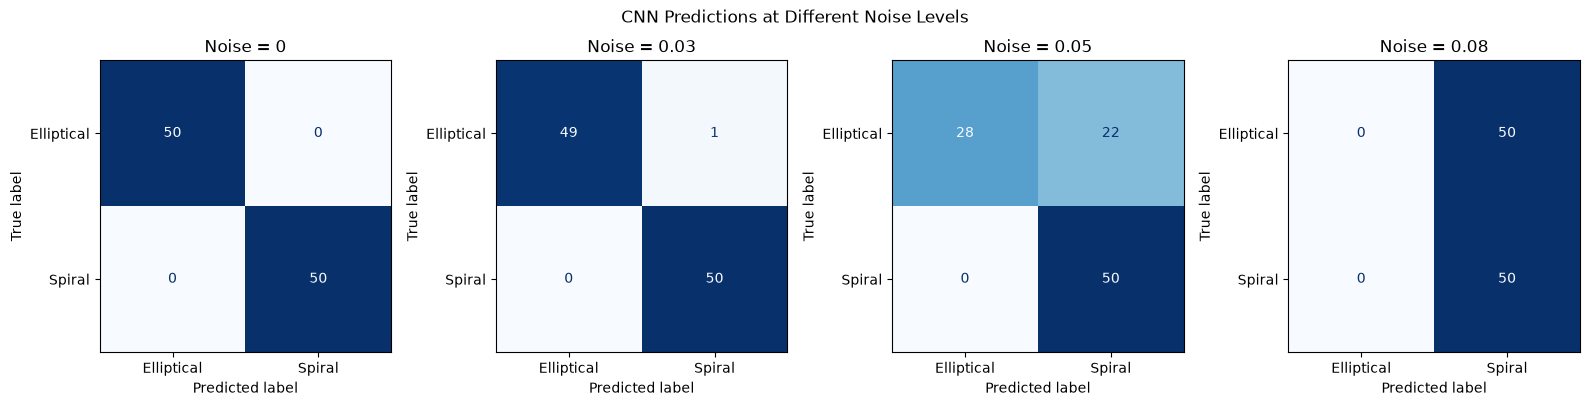

In [21]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

noise_values = [0, 0.03, 0.05, 0.08]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))

rng = np.random.default_rng(42)

for i, noise in enumerate(noise_values):

    noisy_test = x_test + rng.normal(
        0, noise, x_test.shape
    )
    noisy_test = np.clip(noisy_test, 0, 1)

    predictions = model.predict(noisy_test, verbose=0)
    predicted_labels = (predictions[:, 0] >= 0.5).astype(int)

    cm = confusion_matrix(
        y_test, predicted_labels, labels=[0, 1]
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Elliptical", "Spiral"]
    )

    disp.plot(ax=axes[i], cmap="Blues", colorbar=False)
    axes[i].set_title(f"Noise = {noise}")

plt.suptitle("CNN Predictions at Different Noise Levels")
plt.tight_layout()
plt.show()


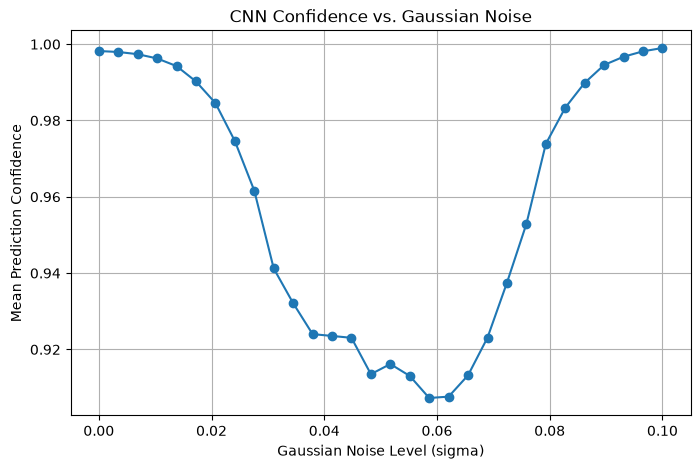

In [22]:

noise_values = np.linspace(0, 0.1, 30)
mean_confidence = []

rng = np.random.default_rng(42)

for noise in noise_values:

    noisy_test = x_test + rng.normal(
        0, noise, x_test.shape
    )
    noisy_test = np.clip(noisy_test, 0, 1)

    predictions = model.predict(noisy_test, verbose=0)

    confidence = np.maximum(
        predictions, 1 - predictions
    )

    mean_confidence.append(np.mean(confidence))

plt.figure(figsize=(8, 5))
plt.plot(noise_values, mean_confidence, marker="o")
plt.xlabel("Gaussian Noise Level (sigma)")
plt.ylabel("Mean Prediction Confidence")
plt.title("CNN Confidence vs. Gaussian Noise")
plt.grid(True)
plt.show()


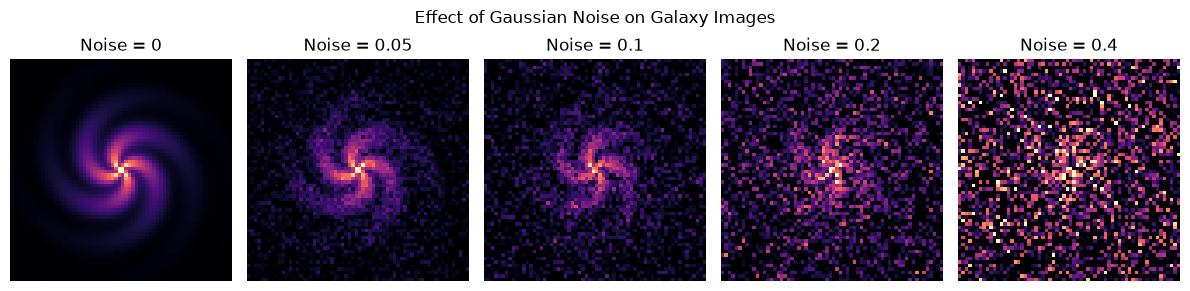

In [26]:

noise_levels = [0, 0.05, 0.1, 0.2, 0.4]

plt.figure(figsize=(12, 3))

original = x_test[0]

for i, noise in enumerate(noise_levels):
    noisy = original + np.random.normal(
        0, noise, original.shape
    )
    noisy = np.clip(noisy, 0, 1)

    plt.subplot(1, 5, i + 1)
    plt.imshow(noisy[:, :, 0], cmap="magma")
    plt.title(f"Noise = {noise}")
    plt.axis("off")

plt.suptitle("Effect of Gaussian Noise on Galaxy Images")
plt.tight_layout()
plt.show()


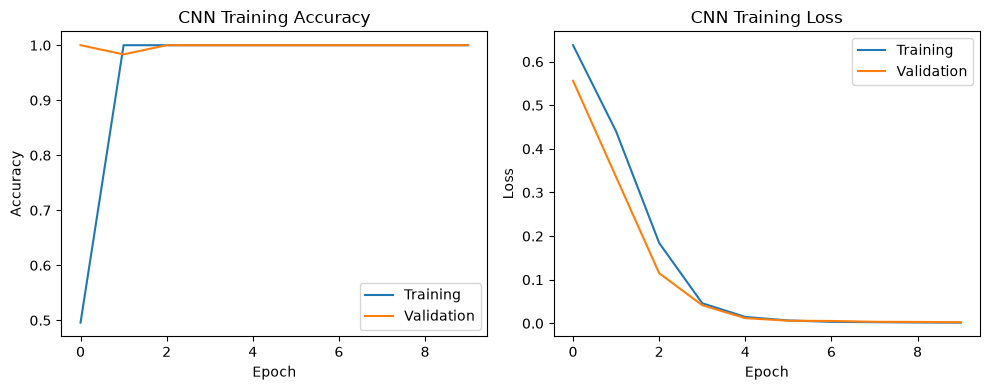

In [13]:

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training")
plt.plot(history.history["val_accuracy"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("CNN Training Accuracy")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training")
plt.plot(history.history["val_loss"], label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training Loss")
plt.legend()

plt.tight_layout()
plt.show()


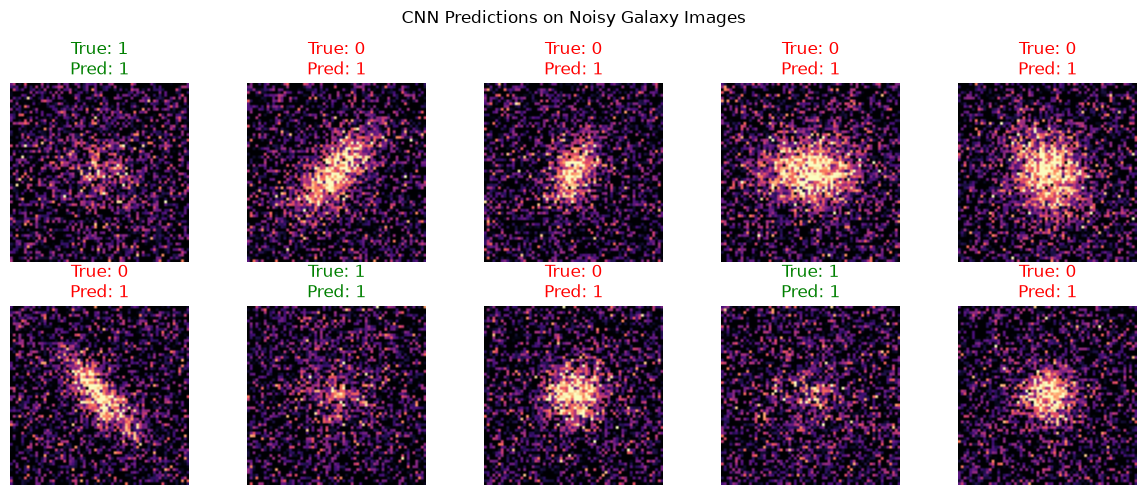

In [14]:

noise = 0.3

noisy_test = x_test + np.random.normal(
    0, noise, x_test.shape
)
noisy_test = np.clip(noisy_test, 0, 1)

predictions = model.predict(noisy_test, verbose=0)

plt.figure(figsize=(12, 5))

for i in range(10):
    predicted = int(predictions[i, 0] >= 0.5)
    actual = y_test[i]

    plt.subplot(2, 5, i + 1)
    plt.imshow(noisy_test[i, :, :, 0], cmap="magma")
    plt.title(
        f"True: {actual}\nPred: {predicted}",
        color="green" if predicted == actual else "red"
    )
    plt.axis("off")

plt.suptitle("CNN Predictions on Noisy Galaxy Images")
plt.tight_layout()
plt.show()


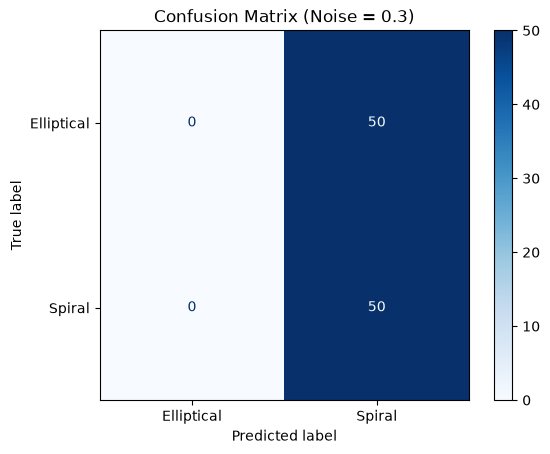

In [27]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

predicted_labels = (predictions[:, 0] >= 0.5).astype(int)

cm = confusion_matrix(y_test, predicted_labels)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Elliptical", "Spiral"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix (Noise = 0.3)")
plt.show()
